In [1]:
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '1' #Select the GPU Card


import sys

from os import environ
import os
from os import listdir
from os.path import isfile, join

import glob
import cv2
import math
import json
from PIL import Image, ImageDraw
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from random import randint, choice, shuffle, sample
import struct

import binascii 
from binascii import hexlify

from multiprocessing import Pool 
from multiprocessing.dummy import Pool as ThreadPool

import numpy as np
from numpy.linalg import eig, inv

# from sklearn.utils import class_weight
# from sklearn.cluster import KMeans

from skimage import feature, exposure
from skimage.feature import match_template
from skimage.morphology import skeletonize

from scipy.optimize import minimize
from scipy.ndimage import rotate, zoom,shift
from scipy import signal, ndimage
# from scipy.misc import imresize, imsave
from scipy.signal import medfilt

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets


import shutil
import numpy as np
import matplotlib.pyplot as plt
import cv2
import glob
import os
from ipywidgets import interact
from scipy import ndimage
import tensorflow as tf
from tensorflow.keras.models import load_model
import math
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from itertools import product

from scipy.optimize import minimize
from scipy.ndimage import distance_transform_edt
from scipy.optimize import differential_evolution, minimize

2026-05-12 16:08:54.443934: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-12 16:08:54.456667: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778582334.471503 1426790 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778582334.476261 1426790 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-12 16:08:54.491379: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
def process_label(label_file):
    """
    This fucntion takes label files with layers marked from 1 to 9, not 0 to 8
    """
    colors = np.zeros((9,3),dtype=np.uint8)

    #### colors for each label edit accordingly 
    colors[0] = [0, 0, 0]
    colors[1] = [255,0,0]
    colors[2] = [0,255,0]
    colors[3] = [0,0,255]
    colors[4] = [255,255,0]
    colors[5] = [255,0,255] 
    colors[6] = [0, 255, 255]
    colors[7] = [255, 153, 51]
    colors[8] = [255, 255, 255]

    H = np.shape(label_file)[0]
    W = np.shape(label_file)[1]

    img = np.zeros((H,W,3),dtype=np.uint8)
    for i,j in product(range(H),range(W)):
        img[i, j] = colors[label_file[i,j]-1]

    return np.asarray(img)

def rotateImage(img, angle, pivot):
    padX = [img.shape[1] - pivot[0], pivot[0]]
    padY = [img.shape[0] - pivot[1], pivot[1]]
    imgP = np.pad(img, [padY, padX], 'constant')
    imgR = ndimage.rotate(imgP, angle, reshape=False)
    return imgR[padY[0] : -padY[1], padX[0] : -padX[1]]


### Plot ONH geometries on images ========================================================
    #     Layer number convention:
    #     1: VH
    #     2: RNFL
    #     3: Other
    #     4: RPE
    #     5: Corroid
    #     6: Sclera
    #     7: LC
    #     8: Noise
### shape of mat_array should be (200,400). The numpy images of OCT volumes are of size (200,400,6) and 
# so as the numpy arrays of labels. These can directly be given to this function for plotting. Segmentation 
# network predictions give output of size (6,200,400,8). Thus, apply argmax, np.argmax(img_preds, axis=3)+1, 
# to reduce the size into (6,200,400), and then roll the 3rd axis, np.rollaxis(temp, 0,3), to get the desired 
# shape, i.e., (200,400,6).

def PlotONHGeometriesOnImages(mat_array):
    """
    This fucntion takes label files with layers marked from 1 to 9, not 0 to 8
    """

    H = np.shape(mat_array)[0]
    W = np.shape(mat_array)[1]

    
    # label_copy = np.zeros((200,400,3),dtype=np.uint8)
    # geo_data=[]
  
    h_data,img = CalculateONHGeometry(mat_array, OutputFlag=True)  
    label_copy= process_label(mat_array)

    white_col = np.array([255,255,255],dtype=np.uint8)
    green_col = np.array([0,255,0],dtype=np.uint8)
    label_copy[int(h_data[0]):int(h_data[0])+5,int(h_data[1]):int(h_data[1])+5,:] = white_col
    label_copy[int(h_data[2]):int(h_data[2])+5,int(h_data[3]):int(h_data[3])+5,:] = white_col
    label_copy[int(h_data[4]):int(h_data[4])+5,int(h_data[5]):int(h_data[5])+5,:] = white_col
    label_copy[int(h_data[6]):int(h_data[6])+5,int(h_data[7]):int(h_data[7])+5,:] = white_col
    label_copy[int(h_data[20]):int(h_data[20])+5,int(h_data[21]):int(h_data[21])+5,:] = green_col
    label_copy[int(h_data[22]):int(h_data[22])+5,int(h_data[23]):int(h_data[23])+5,:] = green_col

    BM_center_c = int((h_data[1]+h_data[3])/2)
    
    for j in range(H):
        label_copy[j,int(h_data[15]):int(h_data[15])+2,:] = white_col
        label_copy[j,int(h_data[16]):int(h_data[16])+2,:] = white_col

        label_copy[j,BM_center_c:BM_center_c+2,:] = white_col

    return label_copy
    
    
    
    
    
    
### calculate ONH geometreis ==============================================================
#     Layer number convention:
#     1: VH
#     2: RNFL
#     3: GCC
#     4: Other
#     5: RPE
#     6: Corroid
#     7: Sclera
#     8: LC
#     9: Noise
def CalculateONHGeometry(mat, OutputFlag=False):
    """
    This function takes label files with layers marked from 1 to 9, not 0 to 8
    """
    img_h = np.shape(mat)[0]
    img_w = np.shape(mat)[1]

    
    ### RPE layer detection, calculates the number of pixels belonging to the RPE layer 
    ### along the col direction of the image
    VH_id = 1
    RNFL_id = 2
    GCC_id = 3
    Other_id = 4
    RPE_id = 5
    Corroid_id = 6
    Sclera_id = 7
    LC_id = 8
    Noise_id = 9
    
    RPE_layer=[]
    for i in range(0,np.shape(mat)[1]):
        pixel_count = 0
        for j in range(np.shape(mat)[0]):
            if mat[j,i] == RPE_id: ### RPE layer ID
                pixel_count = pixel_count +1
        RPE_layer.append(pixel_count)

    ### BM calculation ==============================================================
    BM_found = False
    BM_start = -1
    BM_end = -1
    minpixel = 60
    tolpixel = 6
    loopcount = 0 
    while BM_found != True:
        minp = int(minpixel*(1-loopcount*0.2))
        tolp = int(tolpixel*(1-loopcount*0.2))
        BM_start = -1
        BM_end = -1
        for i in range(50,len(RPE_layer)-50):
            if RPE_layer[i]==0:
                if np.sum(RPE_layer[i:(i+minp)]) <= tolp and BM_start == -1:
                    BM_start = i
        for i in range(50,len(RPE_layer)-50):    
            j = int(len(RPE_layer)-1-i)
            if RPE_layer[j]==0:
                if np.sum(RPE_layer[j-minp:j]) <= tolp and BM_end == -1:   ###
                    BM_end = j
        if BM_start != -1 and BM_end != -1:
            BM_found = True  

        if loopcount > 4:
            break
        loopcount = loopcount +1


    BM_start_r=-1
    BM_start_c=BM_start
    BM_end_r=-1
    BM_end_c=BM_end

    ### this block is for sanity check. if BM can not be found due to bad segmentation
    ### this function returns an array of zeros. 
    if BM_start == -1 or BM_end == -1 or BM_start-1 <= -1 or BM_end+1 >=400 or BM_start== BM_end :
        if (OutputFlag==True):
            return np.array([0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]),mat # 31 output+mat
        else:
            return np.array([0,0,0,0,0,0,0,0,0,0,0]),mat # 11 params+mat

    BM_cnt = 1
    while BM_start_r==-1 or BM_end_r==-1:
        for i in range(np.shape(mat)[0]):
            if mat[i,BM_start-BM_cnt] == RPE_id and BM_start_r == -1:
                BM_start_r = i
            if mat[i,BM_end+BM_cnt] == RPE_id and BM_end_r ==-1:
                BM_end_r =i
        if BM_cnt > 15:
            break
        BM_cnt +=1

    if BM_start_r==-1 and BM_end_r !=-1:
        BM_start_r = BM_end_r
    elif BM_start_r !=-1 and BM_end_r ==-1:
        BM_end_r = BM_start_r
    else:
        BM_end_r = BM_end_r


    ### rotate image to make BM openings horizontal ==========================
    if np.absolute(BM_start_r-BM_end_r)>12:
        vec_a_i = np.absolute(BM_start_r-BM_end_r)
        vec_a_j = np.absolute(BM_start_c-BM_end_c)
        dist_a = np.sqrt(vec_a_i*vec_a_i+vec_a_j*vec_a_j)
        vec_b_i = 0
        vec_b_j = int(dist_a) 
        dist_b = np.sqrt(vec_b_j*vec_b_j)
        theta = math.acos((vec_a_i*vec_b_i+vec_a_j*vec_b_j)/(dist_a*dist_b))*(180.0/3.141)
        if BM_start_r > BM_end_r:
            theta = theta*(-1.0)

        mat = rotateImage(mat, theta, [BM_start_c,BM_start_r])
#         mat = ndimage.rotate(mat, theta, reshape=False)
        # mat = np.reshape(mat,(200,400)) #NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN
        mat = np.reshape(mat,(img_h,img_w))


    ### pixel lenght
    ### we are resizing the image from (496, 384) to (200,400). so we need to adjust the 
    ### pixel values. 
    #image_width = 4.608 # this is in mm
    #image_height = 1.984 # this is in mm
    #px_len_r = image_height/200 ##  this is length of a pixel along the row direction, unit mm
    #px_len_c = image_width/400 ##  this is length of a pixel along the col direcetion, unit mm
    # ------------> x 
    # |    ----------
    # |    !   img   !
    # |    !         !
    # |    ----------
    # z
    # spectralis voxel specification
    delX = 0.012
    delZ = 0.004
    delY = 0.033
    img_x = 384
    img_z = 496
    
    px_len_r = 0.01 ##  this is length of a pixel along the row direction (z dir), unit mm
    px_len_c = 0.01 ##  this is length of a pixel along the col direcetion (x dir), unit mm

    
    ### ONH cavity area calculation
    VH_Px_cnt = 0
    for i in range(int((BM_start_r+BM_end_r)/2),img_h):
        for j in range(BM_start_c,BM_end_c):
            if mat[i,j]==VH_id:
                VH_Px_cnt = VH_Px_cnt +1
    cavity_area =  VH_Px_cnt*px_len_r*px_len_c*1e6 ## area in micron^2 unit

    ### MRW calculation
    BM_center_c = int((BM_start_c+BM_end_c)/2)
    BM_center_r = int((BM_start_r+BM_end_r)/2)

    MRW_v_start=[]
    MRW_start_rc_vec=[]
    for i in range(BM_start_c,BM_center_c):
        for j in range(np.shape(mat)[0]):
            if mat[j,i]==RNFL_id:
                cup_r=j
                cup_c=i
                dist = np.sqrt(((BM_start_r-cup_r)*px_len_r*1000)**2+((BM_start_c-cup_c)*px_len_c*1000)**2)    #.......
                MRW_v_start.append(dist)
                MRW_start_rc_vec.append((cup_r,cup_c))
                break
    MRW_v_start = np.array(MRW_v_start)
    MRW_start_rc_vec = np.array(MRW_start_rc_vec)
    MRW_start = np.min(MRW_v_start) if len(MRW_v_start) > 0 else 0 ## this is thickness in the unit of micron
    MRW_start_rc = MRW_start_rc_vec[np.argmin(MRW_v_start),:] if len(MRW_v_start) > 0 else (0,0)
    MRW_start_rc = np.array(MRW_start_rc)

    MRW_v_end =[]
    MRW_end_rc_vec=[]
    for i in range(BM_center_c,BM_end_c):
        for j in range(np.shape(mat)[0]):
            if mat[j,i]==RNFL_id:
                cup_r=j
                cup_c=i
                dist = np.sqrt(((BM_end_r-cup_r)*px_len_r*1000)**2+((BM_end_c-cup_c)*px_len_c*1000)**2)
                MRW_v_end.append(dist)
                MRW_end_rc_vec.append((cup_r,cup_c))
                break
    MRW_end = np.min(MRW_v_end) if len(MRW_v_end) > 0 else 0 ## this is thickness in the unit of micron
    MRW_end_rc = MRW_end_rc_vec[np.argmin(MRW_v_end)] if len(MRW_v_end) > 0 else (0,0)
    MRW_end_rc = np.array(MRW_end_rc)
    

    ### cup calculation
    px_lift_for_cup = 10 #0.130/px_len_r ### 140 micron lift from disc location to get cup location

    cup_found = False
    disc_center_r = -1
    minpx = 60
    loopcount = 0 
    px_lift_cnt =0
    cup_start = -1
    cup_end = -1
    while cup_found != True:
        disc_center_r = int(BM_center_r - px_lift_for_cup)
        disc_vector = mat[disc_center_r,BM_start_c:BM_end_c]
        minp = int(minpx*(1-px_lift_cnt*0.2))
        cup_start = -1
        cup_end = -1
        for i in range(len(disc_vector)):
            if disc_vector[i]==VH_id:
                if np.sum(disc_vector[i:(i+minp)]) <= minp and (i+minp) < len(disc_vector) and  cup_start == -1:
                    cup_start = i
        for i in range(len(disc_vector)):
            j = int(len(disc_vector)-1-i)
            if disc_vector[j]==VH_id:
                if np.sum(disc_vector[j-minp:j]) <= minp and (j-minp) >0  and cup_end == -1:   ###
                    cup_end = j
        if cup_start != -1 and cup_end != -1:
            cup_found = True  

        if px_lift_cnt > 3:
            px_lift_for_cup = px_lift_for_cup +3
            px_lift_cnt =-1

        if loopcount > 15:
            break
        loopcount = loopcount +1
        px_lift_cnt = px_lift_cnt+1

    cup_start_c = cup_start+BM_start_c
    cup_start_r = disc_center_r
    cup_end_c = cup_end+BM_start_c
#     print(cup_found,cup_start_c,cup_end_c)

    ### ONH parameter calculation
    disc_size = np.absolute(BM_start_c-BM_end_c) *px_len_c*1000 ## unit: micron
    cup_size = np.absolute(cup_start_c-cup_end_c)*px_len_c*1000 ## unit: micron
    if cup_size > 1.1*disc_size or cup_size == 0 or cup_start > cup_end:
        cup_size = 10
        cup_start_c =-1
        cup_end_c =-1


    CDR = cup_size/disc_size
    start_RT = np.absolute(BM_start_c-cup_start_c) if  cup_start_c !=-1 else int(np.absolute(BM_start_c-BM_end_c)/2)    #*px_len_c*1000 ## unit: micron
    end_RT = np.absolute(cup_end_c - BM_end_c) if  cup_end_c !=-1 else int(np.absolute(BM_start_c-BM_end_c)/2)       #*px_len_c*1000 ## unit: micron
    start_RT = start_RT*px_len_c*1000 ## unit: micron
    end_RT = end_RT*px_len_c*1000 ## unit: micron



    ### RNFL, Other and Corroid layer thickness calculation===============
    px_shift_RNFL = 150 #int(1.73/px_len_c) ## number of pixels from the center to measure RNFL thickness

    
    RNFL_start_c = (BM_center_c - px_shift_RNFL) if (BM_center_c - px_shift_RNFL) > 0 else 0
    RNFL_end_c = (BM_center_c + px_shift_RNFL) if (BM_center_c + px_shift_RNFL) < img_w else img_w-1
    if RNFL_start_c > BM_start_c:
        RNFL_start_c = BM_start_c - 5 if (BM_start_c - 5) >0 else BM_start_c
    if RNFL_end_c < BM_end_c:
        RNFL_end_c = BM_end_c +5 if (BM_end_c +5) < img_w else BM_end_c

    px_start_cnt_RNFL=0
    px_end_cnt_RNFL =0
    px_start_cnt_GCC=0
    px_end_cnt_GCC =0
    px_start_cnt_other =0
    px_end_cnt_other =0
    px_start_cnt_Corroid =0
    px_end_cnt_Corroid =0
    for l in range(np.shape(mat)[0]):
        if mat[l,RNFL_start_c] ==RNFL_id: # id RNFL layer
            px_start_cnt_RNFL = px_start_cnt_RNFL+1
        if mat[l,RNFL_end_c] ==RNFL_id: # id RNFL layer
            px_end_cnt_RNFL = px_end_cnt_RNFL+1

        if mat[l,RNFL_start_c] ==GCC_id: # id GCC layer
            px_start_cnt_GCC = px_start_cnt_GCC+1
        if mat[l,RNFL_end_c] ==GCC_id: # id GCC layer
            px_end_cnt_GCC = px_end_cnt_GCC+1
            
        if mat[l,RNFL_start_c] ==Other_id: # id Other layer
            px_start_cnt_other = px_start_cnt_other+1
        if mat[l,RNFL_end_c] ==Other_id: # id Other layer
            px_end_cnt_other = px_end_cnt_other+1

        if mat[l,RNFL_start_c] ==Corroid_id: # id Corroid layer
            px_start_cnt_Corroid = px_start_cnt_Corroid+1
        if mat[l,RNFL_end_c] ==Corroid_id: # id Corroid layer
            px_end_cnt_Corroid = px_end_cnt_Corroid+1


    RNFL_start = px_start_cnt_RNFL* px_len_r *1000 ### thickness unit: micron
    RNFL_end = px_end_cnt_RNFL * px_len_r *1000 ### thickness unit: micron
    GCC_start = px_start_cnt_GCC* px_len_r *1000 ### thickness unit: micron
    GCC_end = px_end_cnt_GCC * px_len_r *1000 ### thickness unit: micron
    Other_start = px_start_cnt_other* px_len_r *1000 ### thickness unit: micron
    Other_end = px_end_cnt_other* px_len_r *1000 ### thickness unit: micron
    Corroid_start = px_start_cnt_Corroid* px_len_r *1000 ### thickness unit: micron
    Corroid_end = px_end_cnt_Corroid* px_len_r *1000 ### thickness unit: micron


    MRW = MRW_start if MRW_start < MRW_end else MRW_end ### thickness unit: micron
    RT = start_RT+end_RT ### thickness unit: micron
    RNFL_thick = (RNFL_start+RNFL_end )/2 ### thickness unit: micron
    GCC_thick = (GCC_start+GCC_end )/2 ### thickness unit: micron
    Other_thick = (Other_start+Other_end)/2 ### thickness unit: micron
    Corroid_thick = (Corroid_start+Corroid_end)/2 ### thickness unit: micron

    ### prelamina and LC combined thickness calculation
    px_cnt_PreLam_LC =0
    for l in range(np.shape(mat)[0]):
        if mat[l,BM_center_c] ==RNFL_id or mat[l,BM_center_c] ==LC_id: # id RNFL layer and id LC
            px_cnt_PreLam_LC = px_cnt_PreLam_LC+1
    PreLam_LC_thick = px_cnt_PreLam_LC* px_len_r *1000 ### thickness unit: micron


    if (OutputFlag==True):
        return np.array([BM_start_r,BM_start_c,BM_end_r,BM_end_c, \
               cup_start_r,cup_start_c,cup_start_r, cup_end_c, \
               MRW_start,MRW_end, disc_size,cup_size,CDR,start_RT,end_RT,\
               RNFL_start_c, RNFL_end_c, RNFL_start,RNFL_end,cavity_area,\
               MRW_start_rc[0],MRW_start_rc[1], MRW_end_rc[0],MRW_end_rc[1],\
               GCC_start,GCC_end,Other_start,Other_end,Corroid_start,Corroid_end,\
               PreLam_LC_thick]),\
               mat ### 31 params+mat
    else:
        return np.array([MRW, disc_size, cup_size, CDR, RT,cavity_area, RNFL_thick, GCC_thick ,Other_thick,Corroid_thick,PreLam_LC_thick]),mat  ### 11 parameters+mat

[0 1 2 3 4 5 6 7]
(200, 400) (200, 400)


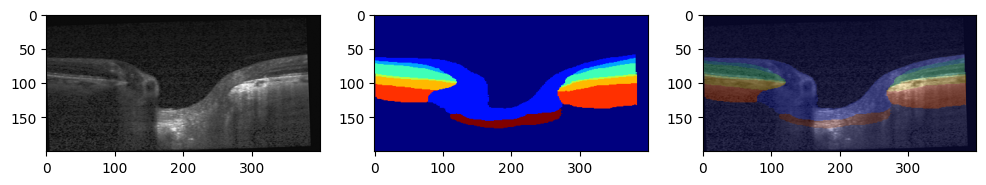

In [3]:
healthy_oct = np.load('/mnt/DATA/sda1/ritu/Data/OCT/Spec_G_BLC_BLC048_34960.npy')
healthy_seg = np.load('/mnt/DATA/sda1/ritu/Data/Label/Spec_G_BLC_BLC048_34960_label.npy')

print(np.unique(healthy_seg))
print(np.shape(healthy_oct), np.shape(healthy_seg))


fig = plt.figure(figsize=(12,9))
plt.subplot(1, 3, 1)
plt.imshow(healthy_oct, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(healthy_seg, cmap='jet')
plt.subplot(1, 3, 3)
plt.imshow(healthy_oct, cmap='gray')
plt.imshow(healthy_seg, cmap='jet', alpha = 0.25)
plt.show()

          MRW  disc_size  cup_size       CDR     RT  cavity_area  RNFL_thick  \
0  180.277564     1490.0     950.0  0.637584  540.0     777700.0        75.0   

   GCC_thick  Other_thick  Corroid_thick  PreLam_LC_thick  
0       55.0        150.0          105.0            280.0  


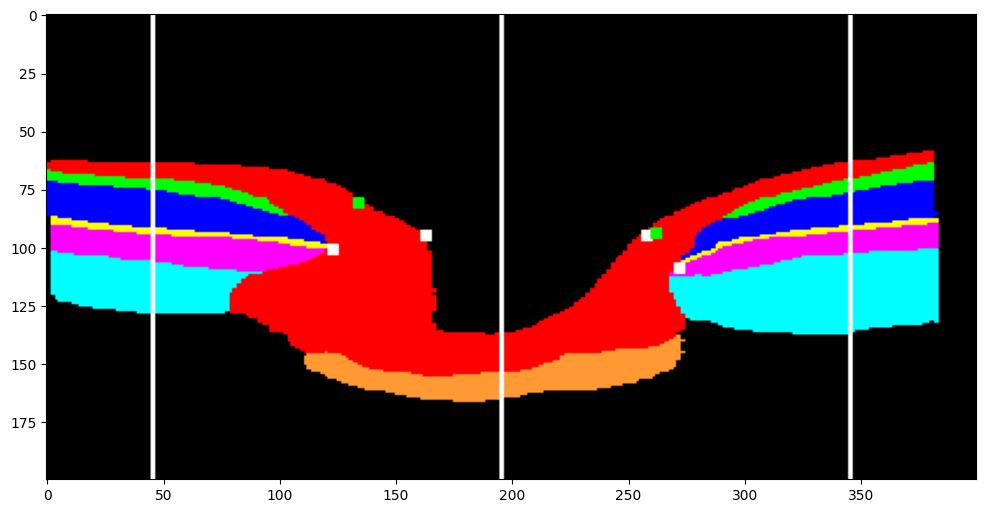

In [4]:
import pandas as pd

params, label = CalculateONHGeometry(healthy_seg+1)

name = ['MRW', 'disc_size', 'cup_size', 'CDR', 'RT','cavity_area', 'RNFL_thick', 'GCC_thick' ,'Other_thick',
        'Corroid_thick','PreLam_LC_thick']
params_df = pd.DataFrame([params], columns=name)
print(params_df)

label_marked = PlotONHGeometriesOnImages(healthy_seg+1)

Image.fromarray(np.array(label_marked, dtype = np.uint8)).save('label_marked.png')

fig = plt.figure(figsize=(12,9))
plt.imshow(label_marked)